In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns

In [ ]:
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 300

# Load raw survey dataset
df_raw = pd.read_csv('data/P5_Dependencies_raw.csv')

print(f"Dataset loaded successfully. Total responses: {df_raw.shape[0]}, Total columns: {df_raw.shape[1]}")
df_raw.head(2)

Dataset loaded successfully. Total responses: 68, Total columns: 28


,Start Date,End Date,Response Type,IP Address,Progress,Duration (in seconds),Finished,Recorded Date,Response ID,Location Latitude,...,How long have you been working with p5.js?,"Generative art sketches often rely on external factors, ranging from libraries and custom assets to hardware capabilities, browser APIs, and runtime environments. We have developed a taxonomy to systematically categorize and analyze these dependencies to better understand how p5.js projects are built, maintained, and preserved.\n\nYour feedback will help us validate and refine this taxonomy so it accurately reflects the real-world practices of the p5.js community.\n\n\n\nInstructions\n\n\tReview the Taxonomy: Below, you will find the proposed taxonomy, including each proposed category, and its definition.\n\tEvaluate Clarity & Completeness: You will be asked to rate how clear the definitions are and whether any dependency types are missing.\n\tInsights: Short text boxes will be available to suggest missing edge cases, highlight overlapping categories, or offer improvements. - How easy the categories are to understand","Generative art sketches often rely on external factors, ranging from libraries and custom assets to hardware capabilities, browser APIs, and runtime environments. We have developed a taxonomy to systematically categorize and analyze these dependencies to better understand how p5.js projects are built, maintained, and preserved.\n\nYour feedback will help us validate and refine this taxonomy so it accurately reflects the real-world practices of the p5.js community.\n\n\n\nInstructions\n\n\tReview the Taxonomy: Below, you will find the proposed taxonomy, including each proposed category, and its definition.\n\tEvaluate Clarity & Completeness: You will be asked to rate how clear the definitions are and whether any dependency types are missing.\n\tInsights: Short text boxes will be available to suggest missing edge cases, highlight overlapping categories, or offer improvements. - How well the categories cover all p5.js dependency types","What specific p5.js libraries, external assets, runtime/hardware dependencies, or code-level patterns are missing or unaddressed by this taxonomy?","Which specific categories did you find ambiguous, difficult to distinguish, or overlapping? Please share any suggestions for renaming or regrouping them",How confident would you feel applying this taxonomy to categorize or audit dependencies in your own p5.js projects?,Did you notice any overlap where a single dependency type could fit into multiple categories simultaneously?,"Which categories overlapped, and under what circumstances?","We want to ensure that the proposed taxonomy is as useful and comprehensive as possible. p5.js projects often involve unique setups (e.g., WebGL shaders, node packages, hardware inputs like webcams/MIDI, or iframe embedding).\n\nBased on your experience developing with p5.js, are there edge cases in your workflow that this taxonomy fails to accommodate?","Do you have any final thoughts, suggestions, or experiences regarding p5.js dependencies that we haven't covered? We’d love to hear your feedback."
0,2026-07-31 10:26:55,2026-07-31 12:52:35,IP Address,132.204.251.253,14,8740,False,2026-08-07 12:52:39,R_3G8tPRUf3uKbAtl,45.5302,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-08-03 06:54:52,2026-08-03 06:55:38,IP Address,5.150.250.194,57,46,False,2026-08-10 06:55:44,R_8D8wPX2OyhXPrkV,59.3326,...,4 to 6 years,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
column_mapping = {
    df_raw.columns[0]: 'start_date',
    df_raw.columns[1]: 'end_date',
    df_raw.columns[2]: 'response_type',
    df_raw.columns[3]: 'ip_address',
    df_raw.columns[4]: 'progress',
    df_raw.columns[5]: 'duration_sec',
    df_raw.columns[6]: 'finished',
    df_raw.columns[7]: 'recorded_date',
    df_raw.columns[8]: 'response_id',
    df_raw.columns[9]: 'latitude',
    df_raw.columns[10]: 'longitude',
    df_raw.columns[11]: 'distribution_channel',
    df_raw.columns[12]: 'user_language',
    df_raw.columns[13]: 'consent',
    df_raw.columns[14]: 'occupation',
    df_raw.columns[15]: 'occupation_other',
    df_raw.columns[16]: 'sector',
    df_raw.columns[17]: 'sector_other',
    df_raw.columns[18]: 'p5js_experience',
    df_raw.columns[19]: 'rating_clarity',
    df_raw.columns[20]: 'rating_completeness',
    df_raw.columns[21]: 'missing_dependencies',
    df_raw.columns[22]: 'ambiguous_categories',
    df_raw.columns[23]: 'confidence_applying',
    df_raw.columns[24]: 'category_overlap_notice',
    df_raw.columns[25]: 'overlapping_categories_detail',
    df_raw.columns[26]: 'edge_cases_unaccommodated',
    df_raw.columns[27]: 'final_thoughts'
}

df = df_raw.rename(columns=column_mapping)

# Convert numeric fields
df['duration_sec'] = pd.to_numeric(df['duration_sec'], errors='coerce')
df['progress'] = pd.to_numeric(df['progress'], errors='coerce')
df['finished'] = df['finished'].astype(bool)

# Filtering overview
total_records = len(df)
consented = df['consent'].str.contains('consent', case=False, na=False).sum()
completed = df['finished'].sum()

print(f"Data Quality Filtering Summary:")
print(f" - Raw Submissions: {total_records}")
print(f" - Consented Submissions: {consented}")
print(f" - Fully Completed Surveys (Progress = 100%): {completed}")

Data Quality Filtering Summary:
 - Raw Submissions: 68
 - Consented Submissions: 67
 - Fully Completed Surveys (Progress = 100%): 22


In [4]:
completed_df = df[df["finished"]]
completed_df.to_csv('completed_responses.csv')

incompleted_df = df[~df["finished"]]
incompleted_df.to_csv('incompleted_responses.csv')

completed_df.head()


,start_date,end_date,response_type,ip_address,progress,duration_sec,finished,recorded_date,response_id,latitude,...,p5js_experience,rating_clarity,rating_completeness,missing_dependencies,ambiguous_categories,confidence_applying,category_overlap_notice,overlapping_categories_detail,edge_cases_unaccommodated,final_thoughts
5,2026-08-11 03:22:06,2026-08-11 03:37:36,IP Address,95.70.205.200,100,930,True,2026-08-11 03:37:37,R_2l8PUk8eMaUBgGd,40.2344,...,4 to 6 years,Moderately clear,Moderately complete,"Browser Security & Permission Policies, p5.ble...",Third-Party Libraries | AI and Machine-Learnin...,Moderately confident,Yes,Web API Endpoints / Data Sources and Persisten...,System & Environment Isolation: Runs inside na...,Automation & Testing Dependencies (Headless Te...
6,2026-08-11 04:06:17,2026-08-11 04:16:23,IP Address,82.169.231.95,100,606,True,2026-08-11 04:16:23,R_2qamqDIRWa0EJF5,52.3759,...,7 to 9 years,Extremely clear,Very complete,NaN,NaN,Moderately confident,Unsure,NaN,Version control and component dependencies. It...,NaN
7,2026-08-11 03:55:59,2026-08-11 04:21:09,IP Address,87.150.123.85,100,1510,True,2026-08-11 04:21:10,R_2s5Oxnw6b3mLQDp,52.5422,...,7 to 9 years,Very clear,Moderately complete,"localHost, broadcast channel API, webHID. \n\n...",NaN,Not at all confident,Unsure,NaN,Yes,Thesis on archiving networked generative art\n...
8,2026-08-11 08:42:10,2026-08-11 08:57:34,IP Address,199.243.143.70,100,924,True,2026-08-11 08:57:35,R_30SggcTDXPui0Am,43.7687,...,7 to 9 years,Very clear,Very complete,NaN,NaN,Very confident,Yes,Most remote resources are accessed via network...,'- Sometimes sketches communicate with the pag...,NaN
9,2026-08-11 09:47:28,2026-08-11 10:03:16,IP Address,93.128.29.227,100,948,True,2026-08-11 10:03:17,R_86hX2poZQmUsFFs,52.4958,...,4 to 6 years,Not at all clear,Not at all complete,"In the taxonomy, https://github.com/golanlevin...",Network protocols seems like a surprisingly l...,Slightly confident,Yes,plotSvg example (see previous answers) - libra...,"The introduction stated, ""We have developed a ...",NaN


In [5]:
# Read the completed file manually because of some manual cleaning of the csv
completed_df = pd.read_csv('completed_responses.csv', index_col=0)
completed_df.head()

,start_date,end_date,response_type,ip_address,progress,duration_sec,finished,recorded_date,response_id,latitude,...,p5js_experience,rating_clarity,rating_completeness,missing_dependencies,ambiguous_categories,confidence_applying,category_overlap_notice,overlapping_categories_detail,edge_cases_unaccommodated,final_thoughts
5,2026-08-11 03:22:06,2026-08-11 03:37:36,IP Address,95.70.205.200,100,930,True,2026-08-11 03:37:37,R_2l8PUk8eMaUBgGd,40.2344,...,4 to 6 years,Moderately clear,Moderately complete,"Browser Security & Permission Policies, p5.ble...",Third-Party Libraries | AI and Machine-Learnin...,Moderately confident,Yes,Web API Endpoints / Data Sources and Persisten...,System & Environment Isolation: Runs inside na...,Automation & Testing Dependencies (Headless Te...
6,2026-08-11 04:06:17,2026-08-11 04:16:23,IP Address,82.169.231.95,100,606,True,2026-08-11 04:16:23,R_2qamqDIRWa0EJF5,52.3759,...,7 to 9 years,Extremely clear,Very complete,NaN,NaN,Moderately confident,Unsure,NaN,Version control and component dependencies. It...,NaN
7,2026-08-11 03:55:59,2026-08-11 04:21:09,IP Address,87.150.123.85,100,1510,True,2026-08-11 04:21:10,R_2s5Oxnw6b3mLQDp,52.5422,...,7 to 9 years,Very clear,Moderately complete,"localHost, broadcast channel API, webHID. \n\n...",NaN,Not at all confident,Unsure,NaN,Yes,Thesis on archiving networked generative art\n...
8,2026-08-11 08:42:10,2026-08-11 08:57:34,IP Address,199.243.143.70,100,924,True,2026-08-11 08:57:35,R_30SggcTDXPui0Am,43.7687,...,7 to 9 years,Very clear,Very complete,NaN,NaN,Very confident,Yes,Most remote resources are accessed via network...,'- Sometimes sketches communicate with the pag...,NaN
9,2026-08-11 09:47:28,2026-08-11 10:03:16,IP Address,93.128.29.227,100,948,True,2026-08-11 10:03:17,R_86hX2poZQmUsFFs,52.4958,...,4 to 6 years,Not at all clear,Not at all complete,"In the taxonomy, https://github.com/golanlevin...",Network protocols seems like a surprisingly l...,Slightly confident,Yes,plotSvg example (see previous answers) - libra...,"The introduction stated, ""We have developed a ...",NaN


# Demographics

In [6]:
def add_count_percentage_labels(ax, total, inside_threshold=7):
    max_width = max(patch.get_width() for patch in ax.patches)

    for patch in ax.patches:
        count = patch.get_width()
        percentage = count / total * 100
        label = f"{int(count)} ({percentage:.1f}%)"

        y = patch.get_y() + patch.get_height() / 2

        if count >= inside_threshold:
            # Larger bars: label inside the bar
            x = count - 0.3
            ha = "right"
            color = "black"
        else:
            # Small bars: label outside the bar
            x = count + 0.3
            ha = "left"
            color = "black"

        ax.text(
            x,
            y,
            label,
            va="center",
            ha=ha,
            color=color,
            fontweight="bold",
            clip_on=False
        )

    ax.set_xlim(0, max_width * 1.25)

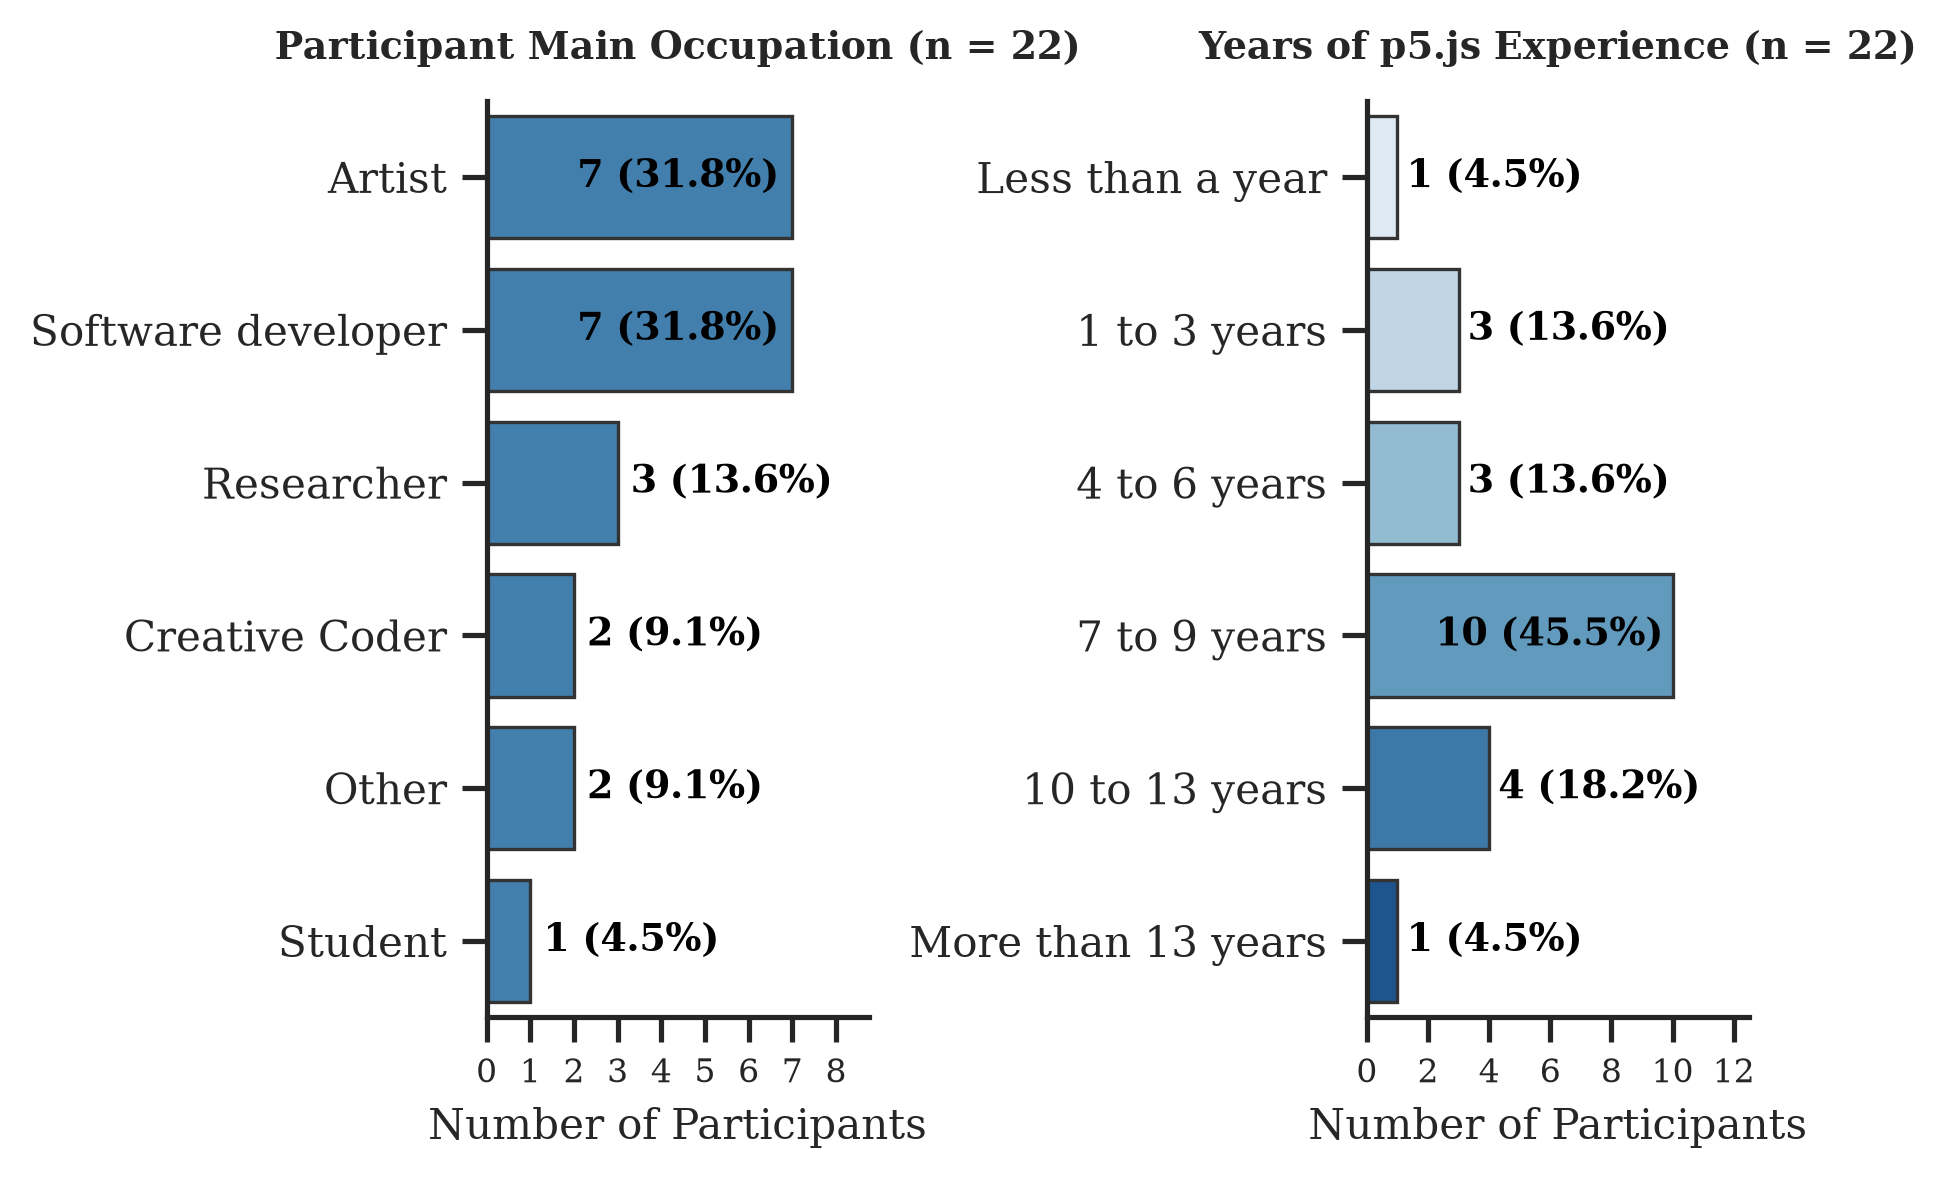

In [7]:
occupation_counts = completed_df['occupation'].dropna().value_counts()
sector_counts = completed_df['sector'].dropna().value_counts()
exp_counts = completed_df['p5js_experience'].dropna().value_counts()

sns.set_theme(style="ticks", font="DejaVu Sans")
plt.rcParams.update({
    "font.family": "serif",           # IEEE uses Times Roman / serif font
    "font.size": 9,                   # Base font size (matches figure captions)
    "axes.labelsize": 10,              # Axis title sizes
    "axes.titlesize": 9,              # Subplot titles
    "xtick.labelsize": 8,             # Axis tick marks
    "ytick.labelsize": 10,             # Axis tick marks
    "figure.autolayout": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})



sns.set_color_codes("pastel")

fig, axes = plt.subplots(1, 2, figsize=(6, 4), dpi=300)

# sns.color_palette("Blues", as_cmap=True)
sns.barplot(
    x=occupation_counts.values, 
    y=occupation_counts.index, 
    ax=axes[0], 
    color='#3182bd',
    legend=False,
    # hue=occupation_counts.index
)
axes[0].set_title(f"Participant Main Occupation (n = {completed_df['occupation'].dropna().count()})", fontweight="bold", pad=10)
axes[0].set_ylabel("")
axes[0].set_xlabel("Number of Participants")
add_count_percentage_labels(
    axes[0],
    occupation_counts.sum()
)

exp_order = ['Less than a year', '1 to 3 years', '4 to 6 years', '7 to 9 years', '10 to 13 years', 'More than 13 years']
exp_filtered = exp_counts.reindex([e for e in exp_order if e in exp_counts.index])

sns.color_palette("Blues", as_cmap=True)
sns.barplot(
    x=exp_filtered.values, 
    y=exp_filtered.index, 
    ax=axes[1], 
    palette="Blues",
    legend=False,
    hue=exp_filtered.index
)
axes[1].set_title(f"Years of p5.js Experience (n = {completed_df['p5js_experience'].dropna().count()})", fontweight="bold", pad=10)
axes[1].set_ylabel("")
axes[1].set_xlabel("Number of Participants")
add_count_percentage_labels(
    axes[1],
    exp_counts.sum()
)

# sec_order = ['Research and education', 'Creative industries', 'Hobby', 'Science and technology', 'Other', 'Communication', 'Government', 'Media and entertainment']
# sec_filtered = sector_counts.reindex([e for e in sec_order if e in sector_counts.index])
#
# sns.barplot(
#     x=sec_filtered.values,
#     y=sec_filtered.index,
#     ax=axes[2],
#     palette="light:b",
#     legend=False,
#     hue=sec_filtered.index
# )
# axes[2].set_title(f"Sector (n = {len(completed_df['sector'])})")
# axes[2].set_xlabel("Number of Participants")
# add_count_percentage_labels(
#     axes[2],
#     sector_counts.sum()
# )

for ax in axes:
    # Integer-only x-ticks
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    for patch in ax.patches:
        patch.set_edgecolor("#333333")
        patch.set_linewidth(0.8)

plt.tight_layout()
plt.savefig('rq1_demographics.pdf', bbox_inches='tight', dpi=300)
plt.show()

    # Quantitative Results

In [8]:
eval_df = completed_df[['rating_clarity', 'rating_completeness', 'confidence_applying', 'category_overlap_notice']].dropna(how='all')

print("=== Taxonomy Category Clarity ===")
print(eval_df['rating_clarity'].value_counts(dropna=True))

print("\n=== Taxonomy Coverage Completeness ===")
print(eval_df['rating_completeness'].value_counts(dropna=True))

print("\n=== Application Confidence ===")
print(eval_df['confidence_applying'].value_counts(dropna=True))

print("\n=== Category Overlap Observed ===")
print(eval_df['category_overlap_notice'].value_counts(dropna=True))

=== Taxonomy Category Clarity ===
rating_clarity
Very clear          12
Moderately clear     5
Extremely clear      4
Not at all clear     1
Name: count, dtype: int64

=== Taxonomy Coverage Completeness ===
rating_completeness
Very complete          14
Moderately complete     6
Not at all complete     2
Name: count, dtype: int64

=== Application Confidence ===
confidence_applying
Moderately confident    10
Very confident           6
Slightly confident       3
Not at all confident     2
Extremely confident      1
Name: count, dtype: int64

=== Category Overlap Observed ===
category_overlap_notice
Yes       11
No         6
Unsure     5
Name: count, dtype: int64


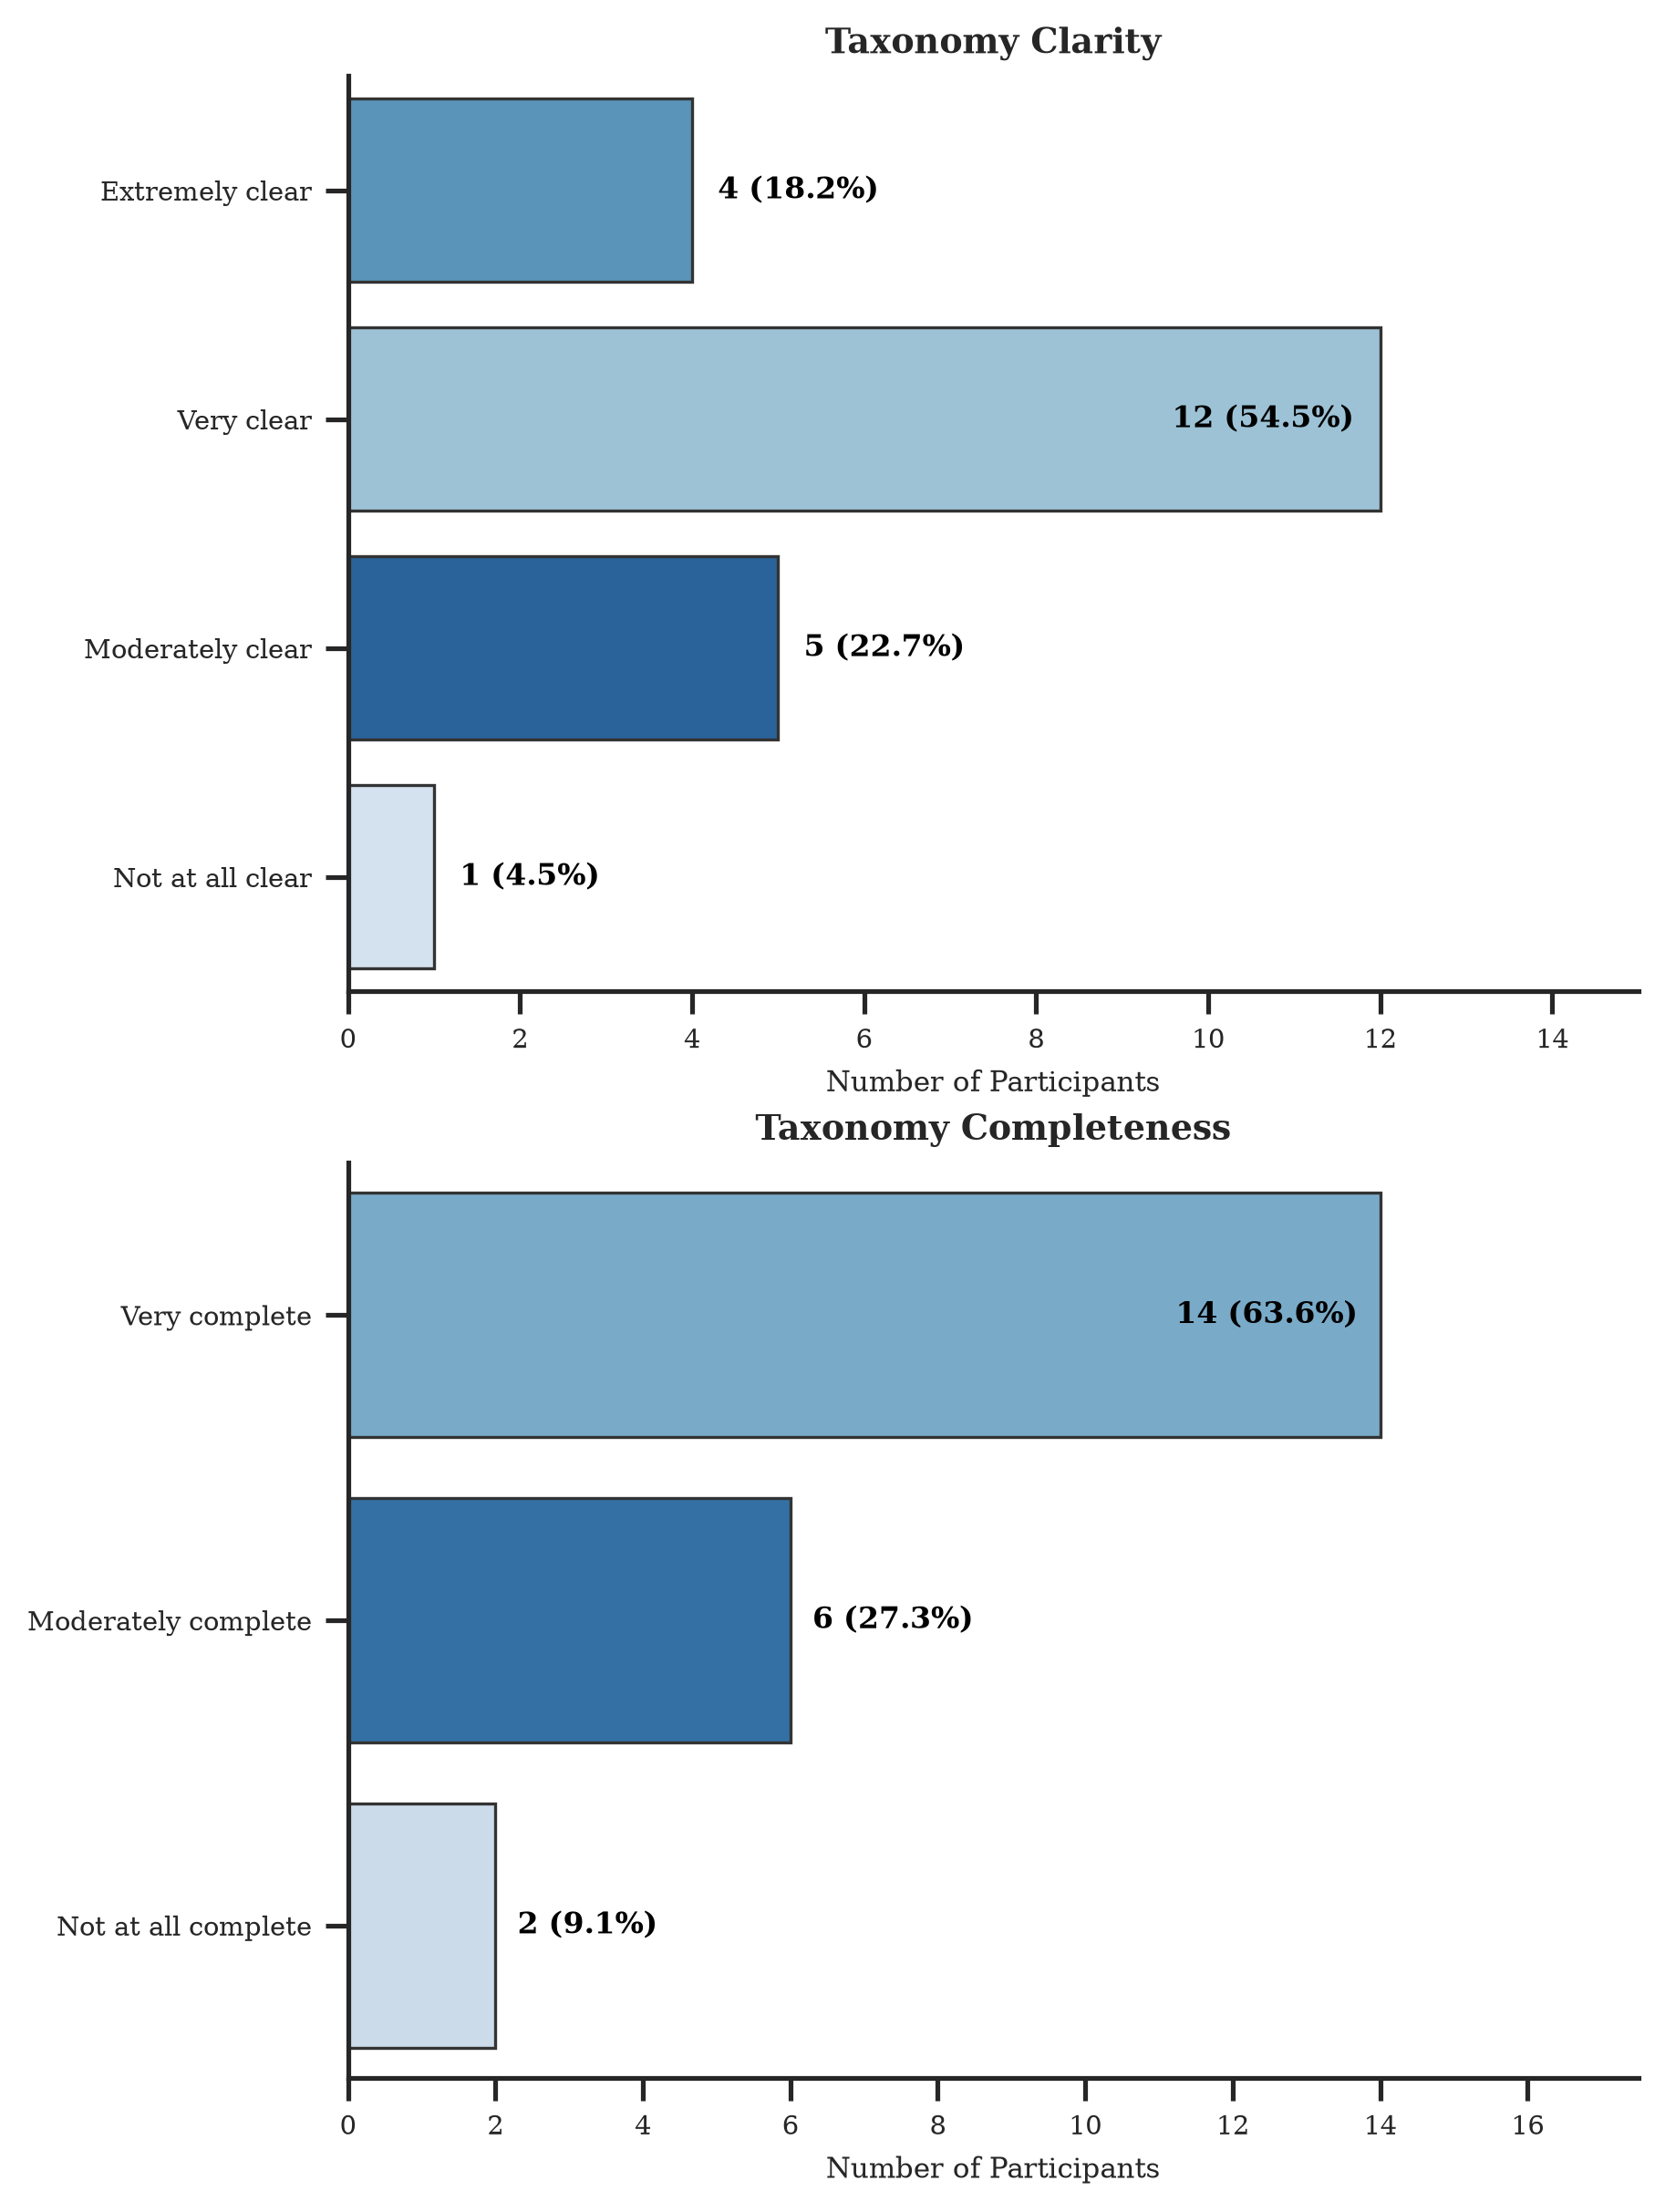

In [9]:
sns.set_theme(style="ticks", font="DejaVu Sans")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "figure.autolayout": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

sns.set_color_codes("pastel")

# Correct 2x1 grid -> axes is a 1D array of 2 elements [axes[0], axes[1]]
fig, axes = plt.subplots(2, 1, figsize=(6, 8), dpi=300)

clarity_order = ['Extremely clear', 'Very clear', 'Moderately clear', 'Not at all clear']
completeness_order = ['Very complete', 'Moderately complete', 'Not at all complete']

# --- Plot 1 (Top: axes[0]) ---
sns.countplot(
    y='rating_clarity',
    data=completed_df,
    order=[o for o in clarity_order if o in completed_df['rating_clarity'].values],
    ax=axes[0],
    palette="Blues_r",
    legend=False,
    hue='rating_clarity'
)

axes[0].set_title("Taxonomy Clarity", fontweight="bold", pad=6)
axes[0].set_xlabel("Number of Participants", fontsize=7.5)
axes[0].set_ylabel("")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))

add_count_percentage_labels(
    axes[0],
    completed_df['rating_clarity'].notna().sum()
)

# --- Plot 2 (Bottom: axes[1]) ---
sns.countplot(
    y='rating_completeness', 
    data=completed_df,
    order=[o for o in completeness_order if o in completed_df['rating_completeness'].values],
    ax=axes[1],
    palette="Blues_r",
    legend=False,
    hue='rating_completeness'
)

axes[1].set_title("Taxonomy Completeness", fontweight="bold", pad=6)
axes[1].set_ylabel("")
axes[1].set_xlabel("Number of Participants", fontsize=7.5)
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))

add_count_percentage_labels(
    axes[1],
    completed_df['rating_completeness'].notna().sum()
)

# --- Format patches across all axes ---
for ax in axes:
    for patch in ax.patches:
        patch.set_edgecolor("#333333")
        patch.set_linewidth(0.8)

plt.tight_layout(pad=0.5)
plt.savefig('rq1_results_2.pdf', bbox_inches='tight', dpi=300)
plt.show()

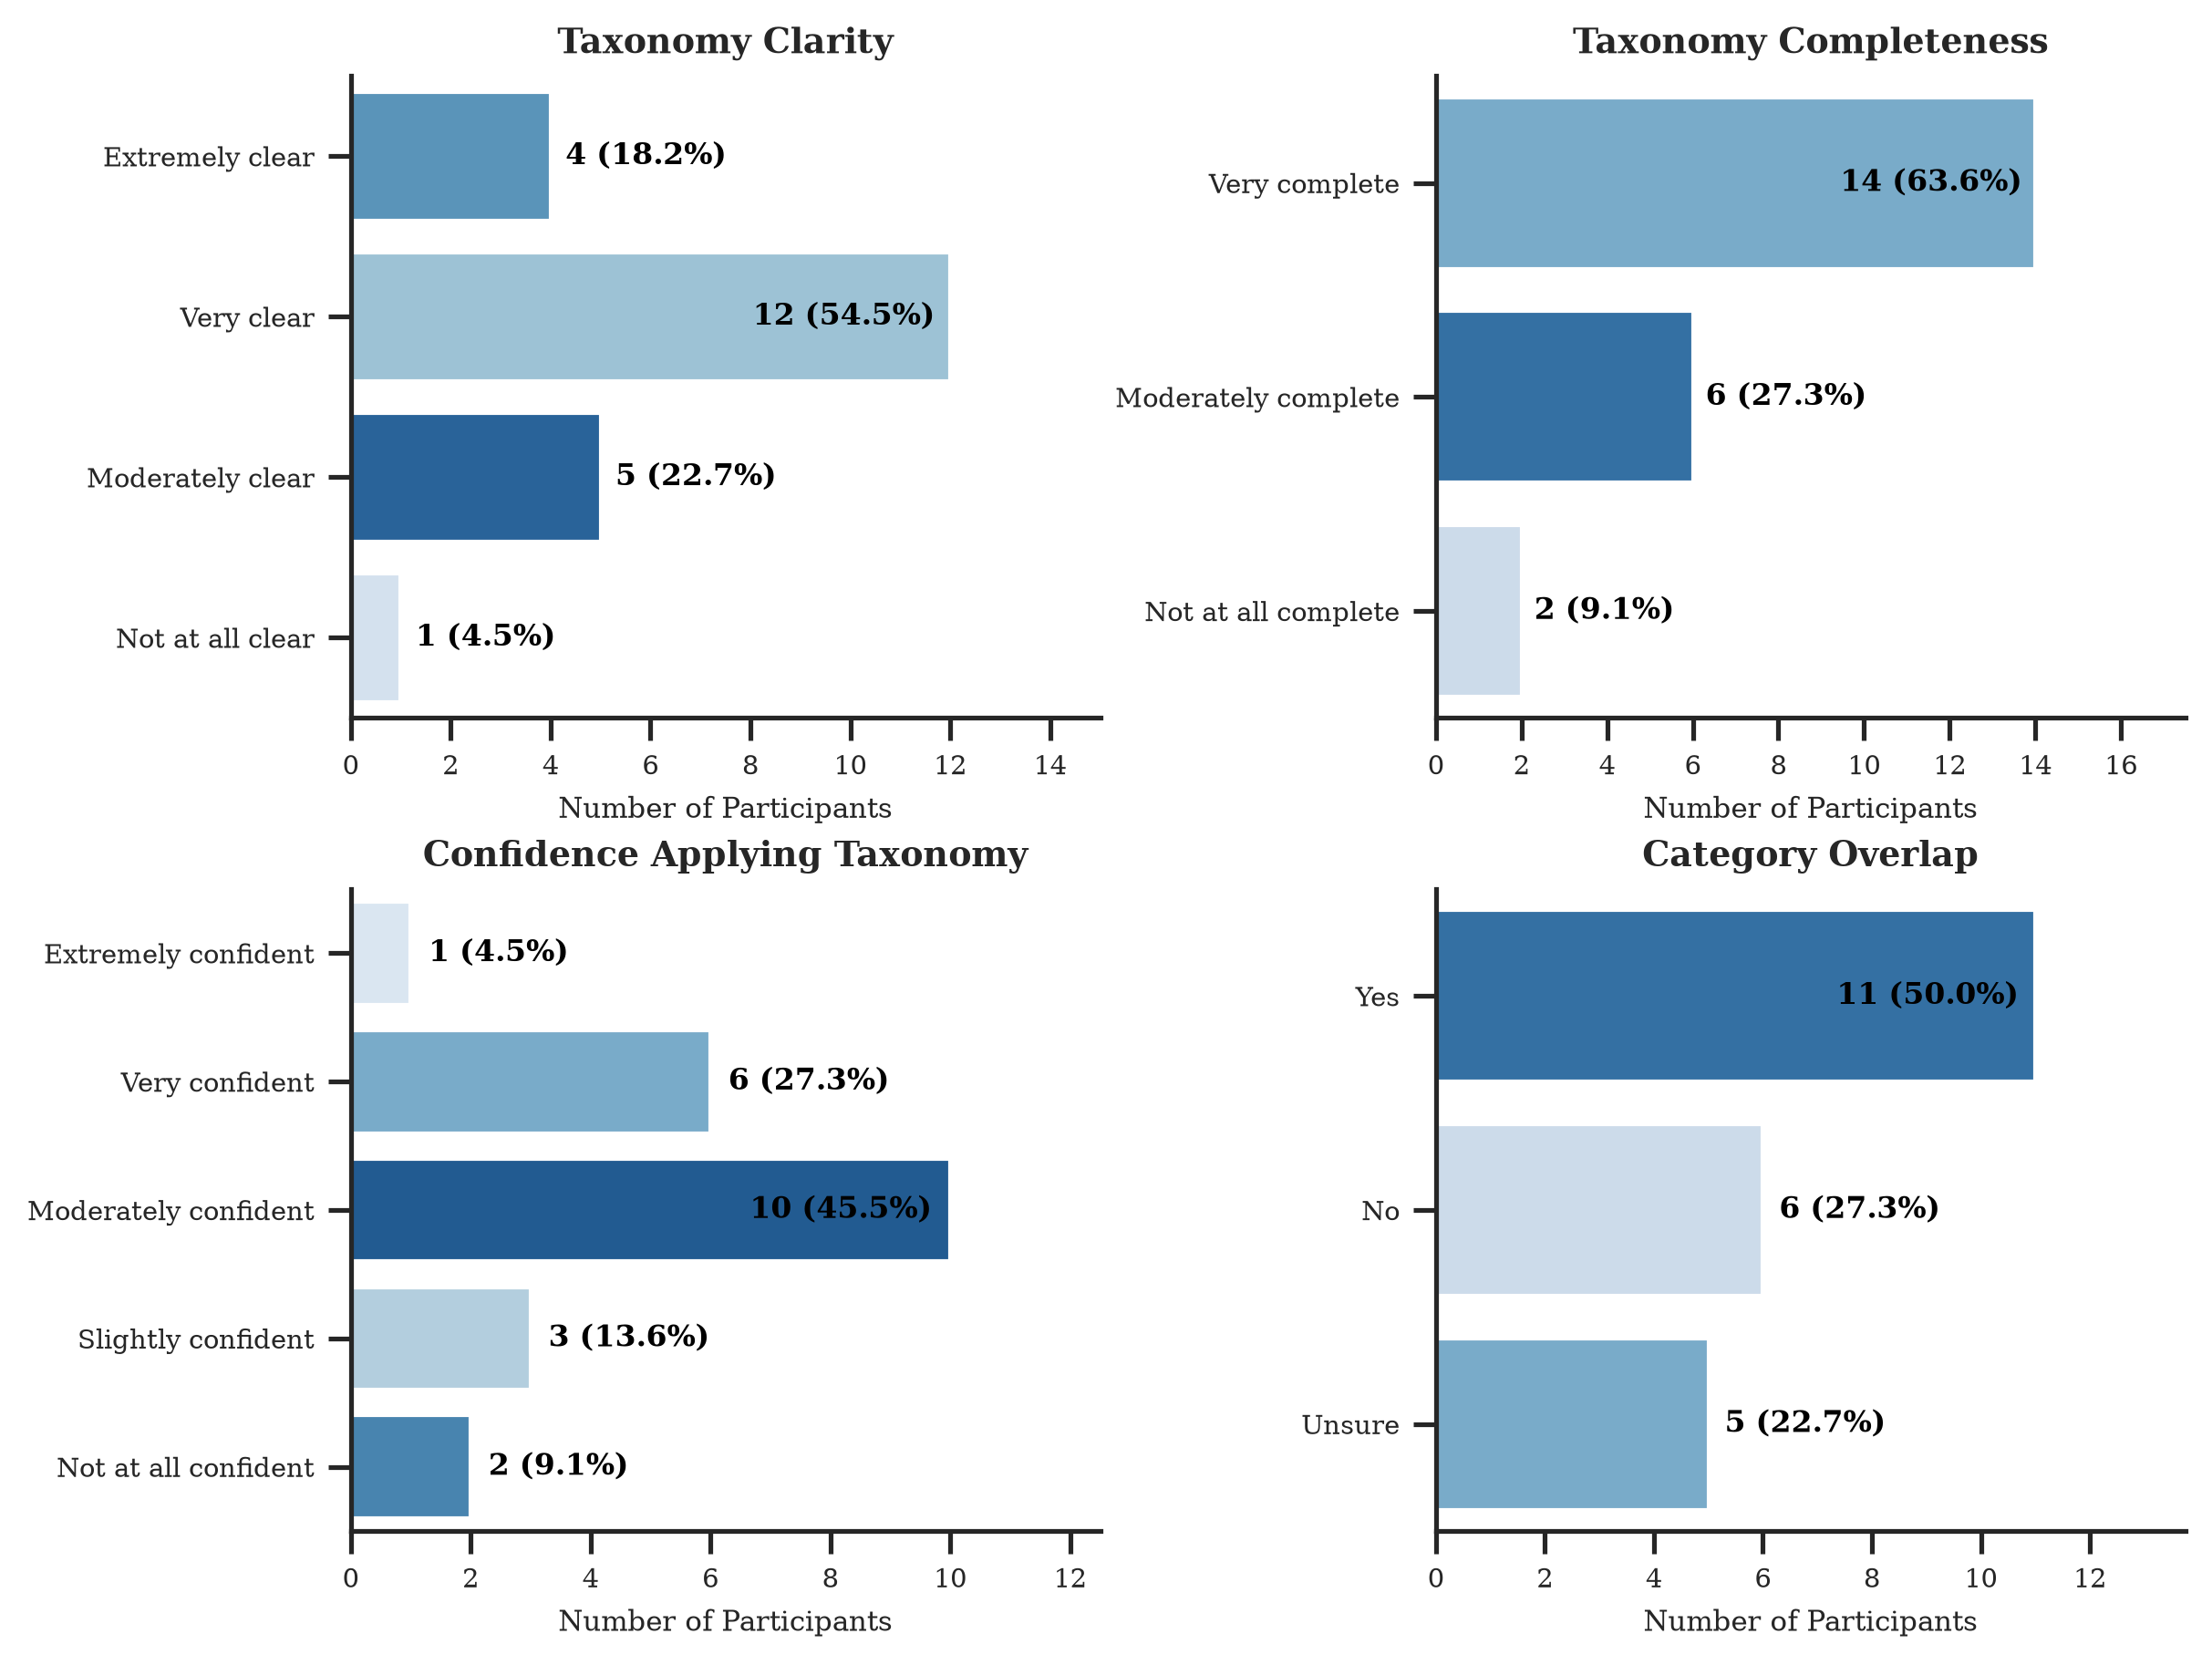

In [10]:
sns.color_palette("Blues", as_cmap=True)
sns.set_theme(style="ticks", font="DejaVu Sans")
# plt.rcParams.update({
#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 11,
#     "xtick.labelsize": 9,
#     "ytick.labelsize": 9,
#     "axes.spines.top": False,
#     "axes.spines.right": False,
# })

plt.rcParams.update({
    "font.family": "serif",           # IEEE uses Times Roman / serif font
    "font.size": 8,                   # Base font size (matches figure captions)
    "axes.labelsize": 8,              # Axis title sizes
    "axes.titlesize": 9,              # Subplot titles
    "xtick.labelsize": 7,             # Axis tick marks
    "ytick.labelsize": 7,             # Axis tick marks
    "figure.autolayout": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

sns.set_color_codes("pastel")
fig, axes = plt.subplots(2, 2, figsize=(8, 6), dpi=300)

clarity_order = ['Extremely clear', 'Very clear', 'Moderately clear', 'Not at all clear']
completeness_order = ['Very complete', 'Moderately complete', 'Not at all complete']
confidence_order = ['Extremely confident', 'Very confident', 'Moderately confident', 'Slightly confident', 'Not at all confident']
overlap_order = ["Yes", "No", "Unsure"]

sns.countplot(
    y='rating_clarity',
    data=completed_df,
    order=[o for o in clarity_order if o in eval_df['rating_clarity'].values],
    ax=axes[0][0],
    palette="Blues_r",
    legend=False,
    hue='rating_clarity'
)
# axes[0].set_title("Category Clarity")
# axes[0].set_ylabel("Taxonomy Clarity")
axes[0][0].set_title("Taxonomy Clarity", fontweight="bold", pad=6)
axes[0][0].set_xlabel("Number of Participants", fontsize=7.5)
axes[0][0].set_ylabel("")
axes[0][0].xaxis.set_major_locator(MaxNLocator(integer=True))
add_count_percentage_labels(
    axes[0][0],
    eval_df['rating_clarity'].notna().sum()
)

sns.countplot(
    y='rating_completeness', 
    data=completed_df,
    order=[o for o in completeness_order if o in eval_df['rating_completeness'].values],
    ax=axes[0][1],
    palette="Blues_r",
    legend=False,
    hue='rating_completeness'
)
axes[0][1].set_title("Taxonomy Completeness", fontweight="bold", pad=6)
axes[0][1].set_ylabel("")
axes[0][1].set_xlabel("Number of Participants", fontsize=7.5)
add_count_percentage_labels(
    axes[0][1],
    eval_df['rating_completeness'].notna().sum()
)

sns.countplot(
    y='confidence_applying', 
    data=completed_df,
    order=[o for o in confidence_order if o in eval_df['confidence_applying'].values],
    ax=axes[1][0],
    palette="Blues_r",
    legend=False,
    hue='confidence_applying'
)
axes[1][0].set_title("Confidence Applying Taxonomy", fontweight="bold", pad=6)
axes[1][0].set_ylabel("")
axes[1][0].set_xlabel("Number of Participants", fontsize=7.5)
axes[1][0].xaxis.set_major_locator(MaxNLocator(integer=True))
add_count_percentage_labels(
    axes[1][0],
    eval_df['confidence_applying'].notna().sum()
)

sns.countplot(
    y='category_overlap_notice',
    data=completed_df,
    order=[o for o in overlap_order if o in eval_df['category_overlap_notice'].values],
    ax=axes[1][1],
    palette="Blues_r",
    legend=False,
    hue='category_overlap_notice'
)

axes[1][1].set_title("Category Overlap", fontweight="bold", pad=6)
axes[1][1].set_ylabel("")
axes[1][1].set_xlabel("Number of Participants", fontsize=7.5)
axes[1][1].xaxis.set_major_locator(MaxNLocator(integer=True))
add_count_percentage_labels(
    axes[1][1],
    eval_df['category_overlap_notice'].notna().sum()
)

for patch in ax.patches:
        patch.set_edgecolor("#333333")
        patch.set_linewidth(0.8)

# fig.suptitle("Taxonomy Evaluation Results", fontsize=16, fontweight="bold")

plt.tight_layout(pad=0.5)
plt.savefig('rq1_results.pdf', bbox_inches='tight', dpi=300)
plt.show()

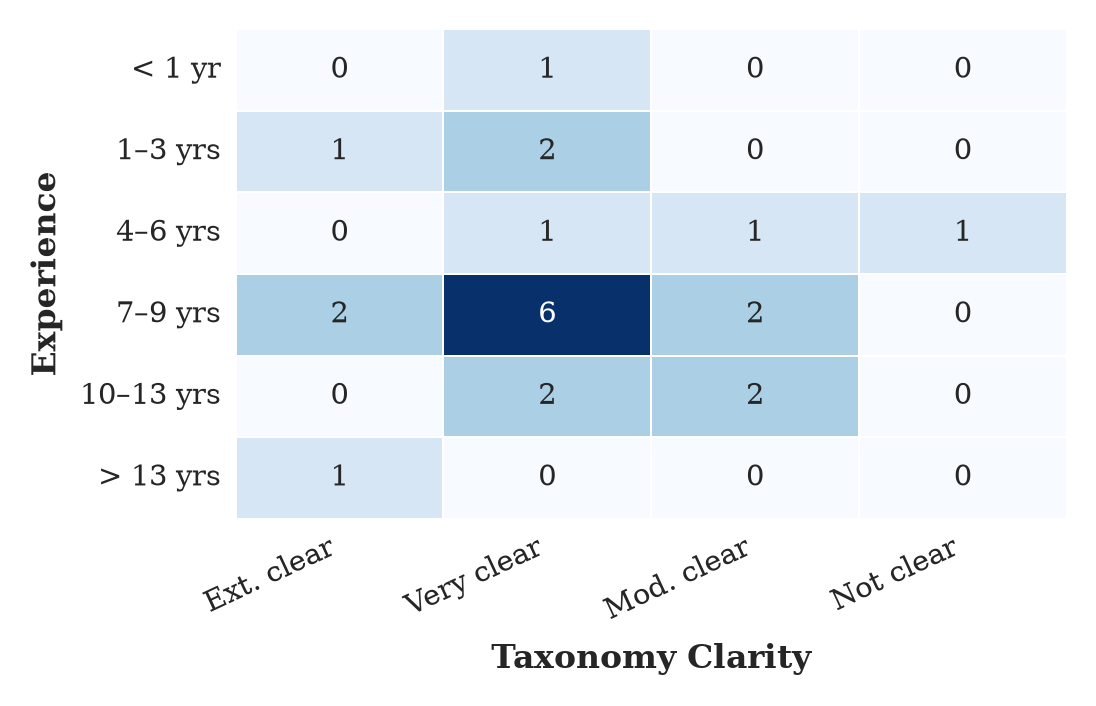

In [11]:
# glue = sns.load_dataset(completed_df).pivot(index="Model", columns="Task", values="Score")

# Cross-tabulation table (frequency counts)
ct = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['rating_clarity'].dropna())

# Reindex to enforce the categorical order and fill missing combinations with 0
ct = ct.reindex(index=exp_order, columns=clarity_order, fill_value=0)

ct.index = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']
ct.columns = ['Ext. clear', 'Very clear', 'Mod. clear', 'Not clear']

# 5. Plot the Heat Map
fig, ax = plt.subplots(figsize=(3.5, 2.2), dpi=300)

# 4. Heatmap Execution
sns.heatmap(
    ct, 
    annot=True,                
    fmt="d", 
    cmap="Blues", 
    cbar=False,                
    linewidths=0.4,
    linecolor='white',
    annot_kws={"size": 7}, 
    ax=ax
)

# 5. Fine-Tuning Titles & Labels
# ax.set_title("Category Clarity vs. p5.js Experience", fontsize=8.5, fontweight='bold', pad=6)
ax.set_ylabel("Experience", fontsize=8, fontweight='bold')
ax.set_xlabel("Taxonomy Clarity", fontsize=8, fontweight='bold')      # Removed dummy label

# Remove tick marks, refine tick label orientation & positioning
ax.tick_params(axis='both', which='both', length=0)

plt.xticks(rotation=25, ha='right', fontsize=7)
plt.yticks(rotation=0, fontsize=7)

# 6. Save Vector PDF for LaTeX
plt.tight_layout(pad=0.2)
plt.savefig('experience_vs_clarity.pdf', bbox_inches='tight', dpi=300)
plt.show()

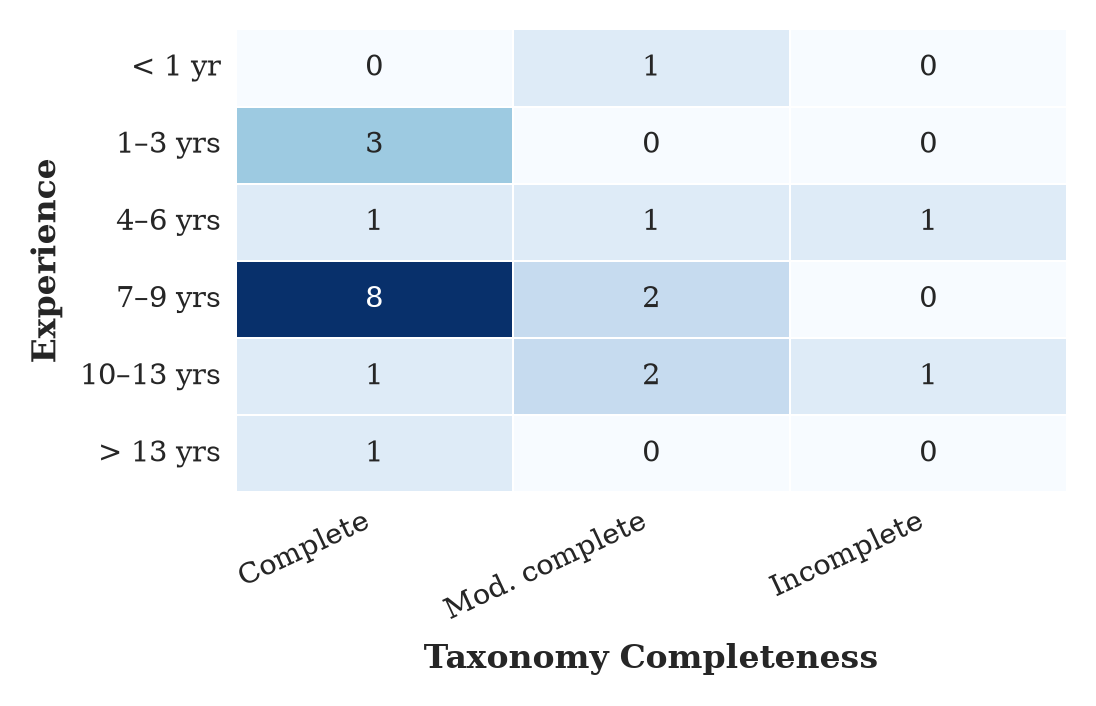

In [12]:
# glue = sns.load_dataset(completed_df).pivot(index="Model", columns="Task", values="Score")

# Cross-tabulation table (frequency counts)
ct = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['rating_completeness'].dropna())

# Reindex to enforce the categorical order and fill missing combinations with 0
ct = ct.reindex(index=exp_order, columns=completeness_order, fill_value=0)

ct.index = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']
ct.columns = ['Complete', 'Mod. complete', 'Incomplete']

# 5. Plot the Heat Map
fig, ax = plt.subplots(figsize=(3.5, 2.2), dpi=300)

# 4. Heatmap Execution
sns.heatmap(
    ct, 
    annot=True,                
    fmt="d", 
    cmap="Blues", 
    cbar=False,                
    linewidths=0.4,
    linecolor='white',
    annot_kws={"size": 7}, 
    ax=ax
)

# 5. Fine-Tuning Titles & Labels
# ax.set_title("Category Clarity vs. p5.js Experience", fontsize=8.5, fontweight='bold', pad=6)
ax.set_ylabel("Experience", fontsize=8, fontweight='bold')
ax.set_xlabel("Taxonomy Completeness", fontsize=8, fontweight='bold')      # Removed dummy label

# Remove tick marks, refine tick label orientation & positioning
ax.tick_params(axis='both', which='both', length=0)

plt.xticks(rotation=25, ha='right', fontsize=7)
plt.yticks(rotation=0, fontsize=7)

# 6. Save Vector PDF for LaTeX
plt.tight_layout(pad=0.2)
plt.savefig('experience_vs_completeness.pdf', bbox_inches='tight', dpi=300)
plt.show()

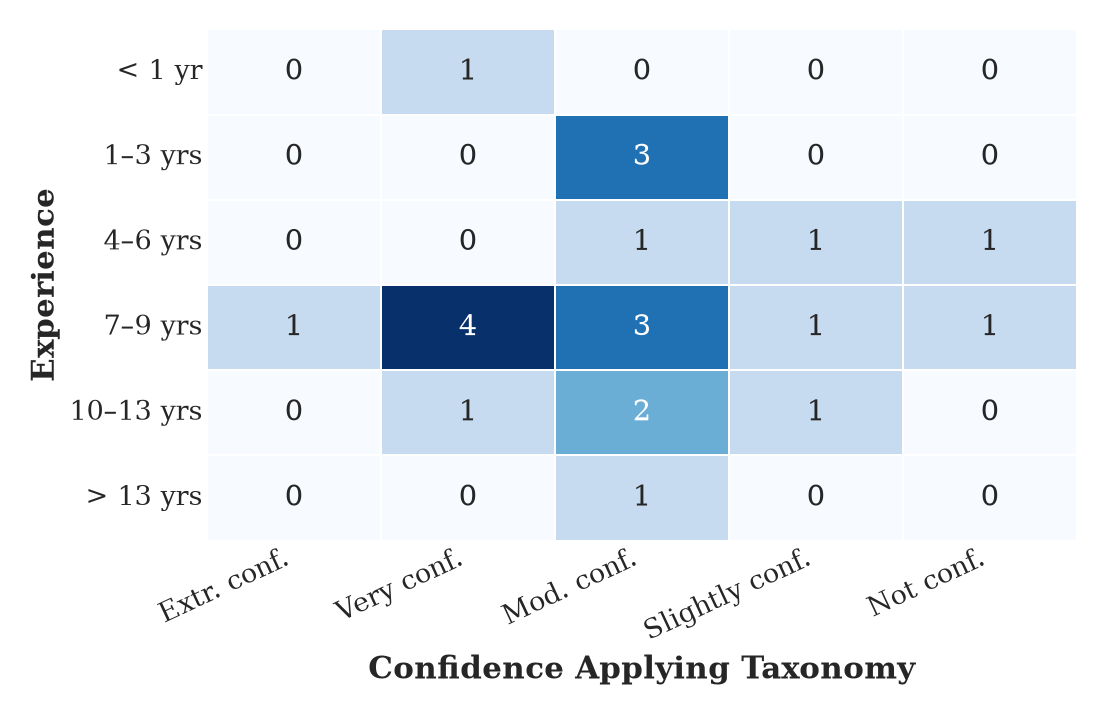

In [13]:
# 1. Styling & Data Preparation
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 8

ct = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['confidence_applying'].dropna())
ct = ct.reindex(index=exp_order, columns=confidence_order, fill_value=0)

ct.index = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']
# Shortened labels slightly to allow tighter horizontal spacing
ct.columns = ['Extr. conf.', 'Very conf.', 'Mod. conf.', 'Slightly conf.', 'Not conf.']

fig, ax = plt.subplots(figsize=(3.5, 2.2), dpi=300)

# 3. Compact Heatmap Execution
sns.heatmap(
    ct, 
    annot=True,                
    fmt="d", 
    cmap="Blues", 
    cbar=False,                
    linewidths=0.4,
    linecolor='white',
    annot_kws={"size": 7}, 
    ax=ax
)

# 4. Compact Axis Formatting
ax.set_ylabel("Experience", fontsize=7.5, fontweight='bold', labelpad=2)
ax.set_xlabel("Confidence Applying Taxonomy", fontsize=7.5, fontweight='bold', labelpad=2)

ax.tick_params(axis='both', which='both', length=0, pad=1)

# Rotate X labels slightly less (25 deg) to minimize bottom margin consumption
plt.xticks(rotation=25, ha='right', fontsize=6.5)
plt.yticks(rotation=0, fontsize=6.5)

# 5. Export with Zero Margin
plt.tight_layout(pad=0.05)
plt.savefig('experience_vs_confidence.pdf', bbox_inches='tight', pad_inches=0.02, dpi=300)
plt.show()

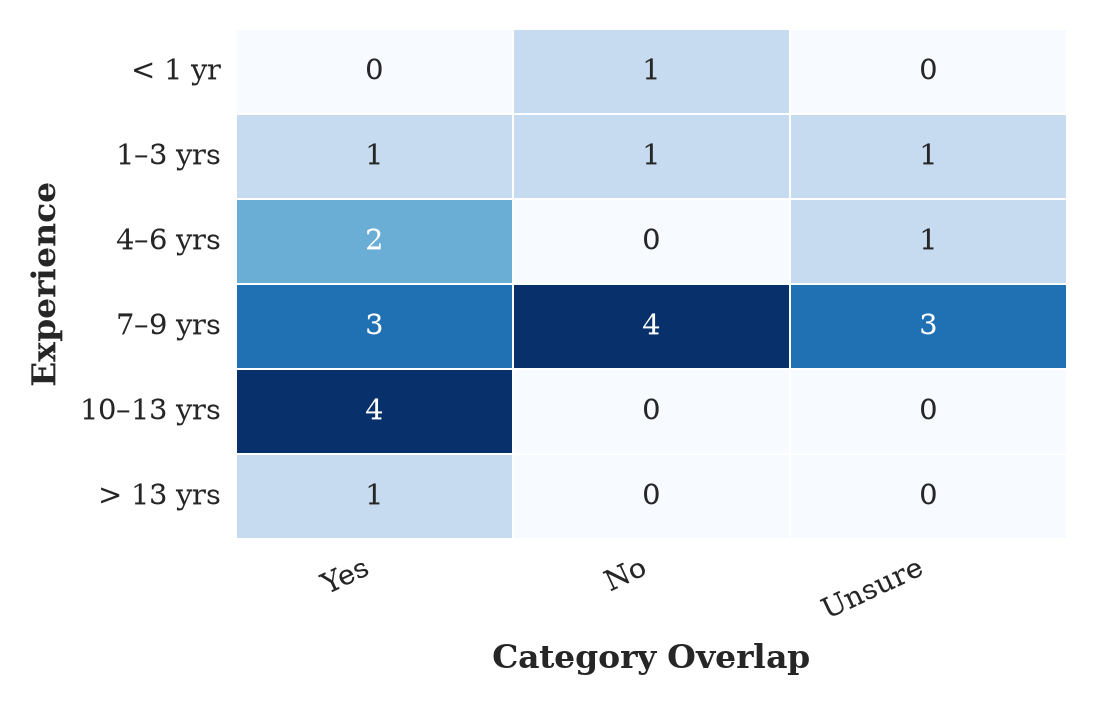

In [14]:
# glue = sns.load_dataset(completed_df).pivot(index="Model", columns="Task", values="Score")

# Cross-tabulation table (frequency counts)
ct = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['category_overlap_notice'].dropna())

# Reindex to enforce the categorical order and fill missing combinations with 0
ct = ct.reindex(index=exp_order, columns=overlap_order, fill_value=0)

ct.index = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']
# ct.columns = ['Extr. confident', 'Very confident', 'Mod. confident', 'Slightly confident', 'Not confident']

# ct.loc['Total'] = ct.sum(axis=0)

# 5. Plot the Heat Map
fig, ax = plt.subplots(figsize=(3.5, 2.2), dpi=300)

# 4. Heatmap Execution
sns.heatmap(
    ct, 
    annot=True,                
    fmt="d", 
    cmap="Blues", 
    cbar=False,                
    linewidths=0.4,
    linecolor='white',
    annot_kws={"size": 7}, 
    ax=ax
)

# 5. Fine-Tuning Titles & Labels
# ax.set_title("Category Clarity vs. p5.js Experience", fontsize=8.5, fontweight='bold', pad=6)
ax.set_ylabel("Experience", fontsize=8, fontweight='bold')
ax.set_xlabel("Category Overlap", fontsize=8, fontweight='bold')      # Removed dummy label

# Remove tick marks, refine tick label orientation & positioning
ax.tick_params(axis='both', which='both', length=0)

plt.xticks(rotation=25, ha='right', fontsize=7)
plt.yticks(rotation=0, fontsize=7)

# for ax in axes:
#     # Integer-only x-ticks
#     ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# 6. Save Vector PDF for LaTeX
plt.tight_layout(pad=0.2)
plt.savefig('experience_vs_overlap.pdf', bbox_inches='tight', dpi=300)
plt.show()

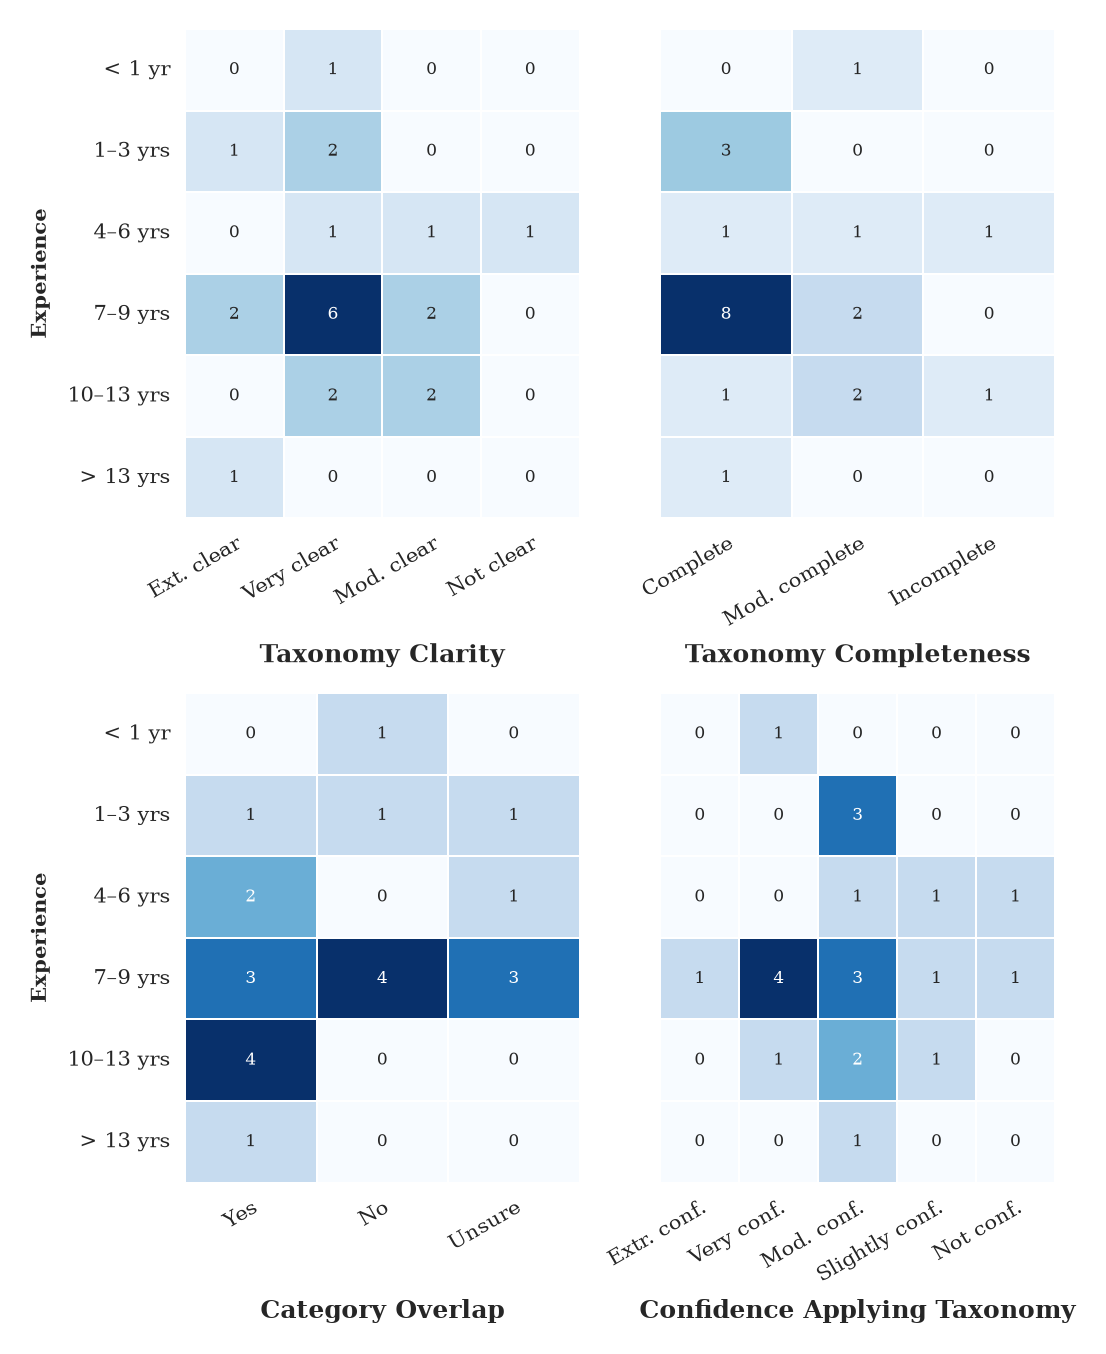

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Global typography styling for IEEE papers
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 6,
    'axes.labelsize': 5,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
})

exp_labels = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']

# 1. Prepare Data
ct_clarity = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['rating_clarity'].dropna()) \
    .reindex(index=exp_order, columns=clarity_order, fill_value=0)
ct_clarity.index = exp_labels
ct_clarity.columns = ['Ext. clear', 'Very clear', 'Mod. clear', 'Not clear']

ct_completeness = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['rating_completeness'].dropna()) \
    .reindex(index=exp_order, columns=completeness_order, fill_value=0)
ct_completeness.index = exp_labels
ct_completeness.columns = ['Complete', 'Mod. complete', 'Incomplete']

ct_confidence = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['confidence_applying'].dropna()) \
    .reindex(index=exp_order, columns=confidence_order, fill_value=0)
ct_confidence.index = exp_labels
ct_confidence.columns = ['Extr. conf.', 'Very conf.', 'Mod. conf.', 'Slightly conf.', 'Not conf.']

ct_overlap = pd.crosstab(completed_df['p5js_experience'].dropna(), completed_df['category_overlap_notice'].dropna()) \
    .reindex(index=exp_order, columns=overlap_order, fill_value=0)
ct_overlap.index = exp_labels

# 2. Build 2x2 Grid Figure
fig, axes = plt.subplots(2, 2, figsize=(3.5, 4.4), sharey=True, layout='constrained')

plots = [
    (axes[1, 0], ct_overlap, "Category Overlap"),
    (axes[0, 0], ct_clarity, "Taxonomy Clarity"),
    (axes[1, 1], ct_confidence, "Confidence Applying Taxonomy"),
    (axes[0, 1], ct_completeness, "Taxonomy Completeness"),
]

for ax, data, xlabel in plots:
    sns.heatmap(
        data,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        linewidths=0.4,
        linecolor='white',
        annot_kws={"size": 4},
        ax=ax
    )
    
    ax.set_xlabel(xlabel, fontweight='bold', labelpad=3, fontsize=6)
    ax.tick_params(axis='both', which='both', length=0)
    
    # Precise anchor alignment for rotated text
    plt.setp(
        ax.get_xticklabels(), 
        rotation=30, 
        ha='right', 
        va='top',
        rotation_mode='anchor'
    )
    plt.setp(ax.get_yticklabels(), rotation=0)

# Set Y-axis label on left-side plots only
axes[0, 0].set_ylabel("Experience", fontweight='bold', fontsize=5)
axes[1, 0].set_ylabel("Experience", fontweight='bold', fontsize=5)

# Align x-axis labels horizontally across each row
fig.align_xlabels()

plt.savefig('taxonomy_evaluation_2x2.pdf', bbox_inches='tight', pad_inches=0.02, dpi=300)
plt.show()

/var/folders/rm/jpz9s5s53h1gyb3l6pg_h57r0000gn/T/ipykernel_94393/943843098.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('taxonomy_evaluation_2d.pdf', bbox_inches='tight', pad_inches=0.02)
/Users/mauricio/.cache/uv/archive-v0/ENKjZA8BLol8Wjn47Srnw/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


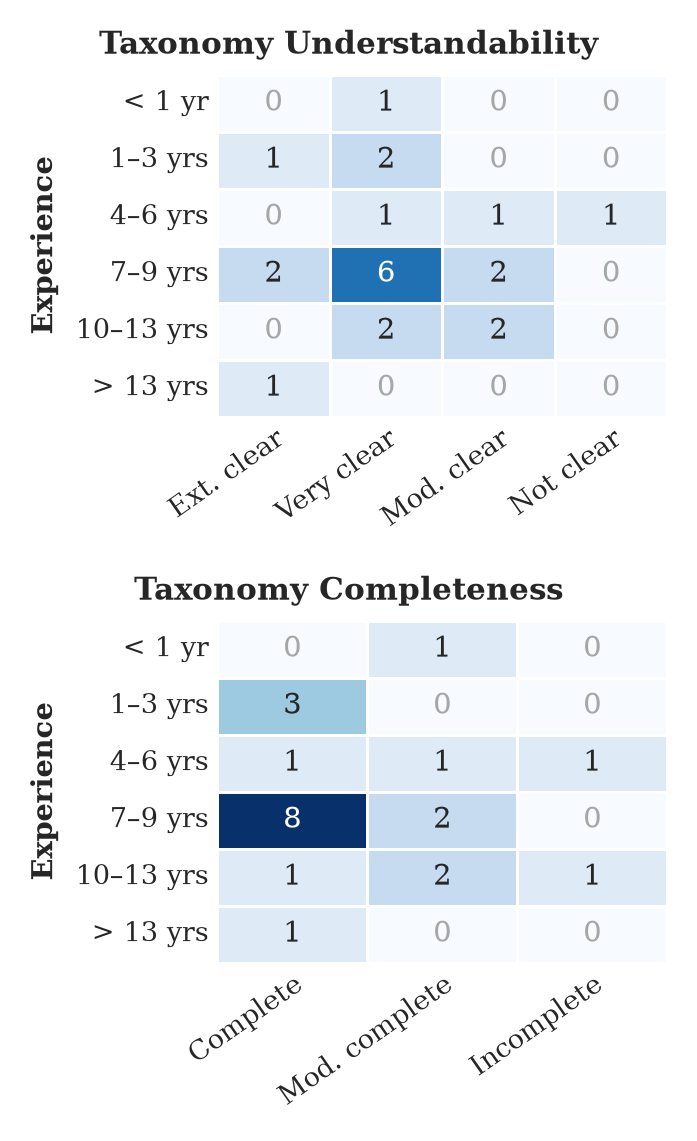

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------------------------
# Typography (IEEE: figure text should stay legible at ~7-8 pt when printed)
# ---------------------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 7,
    'axes.titlesize': 7.5,
    'axes.labelsize': 7,
    'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5,
    'pdf.fonttype': 42,   # embed TrueType fonts (IEEE PDF eXpress friendly)
    'ps.fonttype': 42,
})

exp_labels = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']


# ---------------------------------------------------------------------------
# 1. Prepare data
# ---------------------------------------------------------------------------
def build_ct(column, order, col_labels):
    ct = (pd.crosstab(completed_df['p5js_experience'], completed_df[column])
            .reindex(index=exp_order, columns=order, fill_value=0))
    ct.index = exp_labels
    ct.columns = col_labels
    return ct


ct_clarity = build_ct('rating_clarity', clarity_order,
                      ['Ext. clear', 'Very clear', 'Mod. clear', 'Not clear'])
ct_completeness = build_ct('rating_completeness', completeness_order,
                           ['Complete', 'Mod. complete', 'Incomplete'])

panels = [
    (ct_clarity, 'Taxonomy Understandability'),
    (ct_completeness, 'Taxonomy Completeness'),
]

# Shared colour scale so shades are comparable between the two panels
vmax = max(ct.values.max() for ct, _ in panels)

# ---------------------------------------------------------------------------
# 2. Layout: both grids share the same width so titles and charts line up
# ---------------------------------------------------------------------------
GRID_W = 1.50   # total width of each heatmap grid (inches)
CELL_H = 0.19   # row height (inches)
LEFT   = 0.62   # room for y tick labels + y label
RIGHT  = 0.05
TOP    = 0.22   # room for the top panel title
GAP    = 0.68   # rotated x tick labels + next panel title
BOTTOM = 0.45   # rotated x tick labels of bottom panel

n_rows = len(exp_labels)
ax_h = n_rows * CELL_H

fig_w = LEFT + GRID_W + RIGHT
fig_h = TOP + ax_h + GAP + ax_h + BOTTOM
fig = plt.figure(figsize=(fig_w, fig_h), layout='none')

bottoms = [BOTTOM + ax_h + GAP, BOTTOM]   # top panel first

for (data, title), bottom in zip(panels, bottoms):
    ax = fig.add_axes([LEFT / fig_w, bottom / fig_h, GRID_W / fig_w, ax_h / fig_h])

    sns.heatmap(
        data,
        annot=True,
        fmt='d',
        cmap='Blues',
        vmin=0,
        vmax=vmax,
        cbar=False,
        linewidths=0.6,
        linecolor='white',
        annot_kws={'size': 7},
        ax=ax,
    )

    # De-emphasise zero cells so the non-zero counts stand out
    for txt in ax.texts:
        if txt.get_text() == '0':
            txt.set_color('0.65')

    ax.set_title(title, loc='center', fontweight='bold', pad=5)
    ax.set_xlabel('')
    ax.set_ylabel('Experience', fontweight='bold')
    ax.tick_params(axis='both', which='both', length=0, pad=2)

    plt.setp(ax.get_xticklabels(), rotation=35, ha='right', va='top',
             rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0)

fig.align_ylabels(fig.axes)

# ---------------------------------------------------------------------------
# 3. Centre each title over the whole panel: y label + y tick labels + grid
# ---------------------------------------------------------------------------
fig.canvas.draw()                       # lay out text so its extent is known
renderer = fig.canvas.get_renderer()
for ax in fig.axes:
    left_px = ax.yaxis.get_tightbbox(renderer).x0   # outer edge of "Experience"
    right_px = ax.bbox.x1                           # right edge of the grid
    centre_px = (left_px + right_px) / 2
    centre_ax = ax.transAxes.inverted().transform((centre_px, 0))[0]
    ax.title.set_x(centre_ax)            # title already has ha='center'

plt.savefig('taxonomy_evaluation_2d.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()

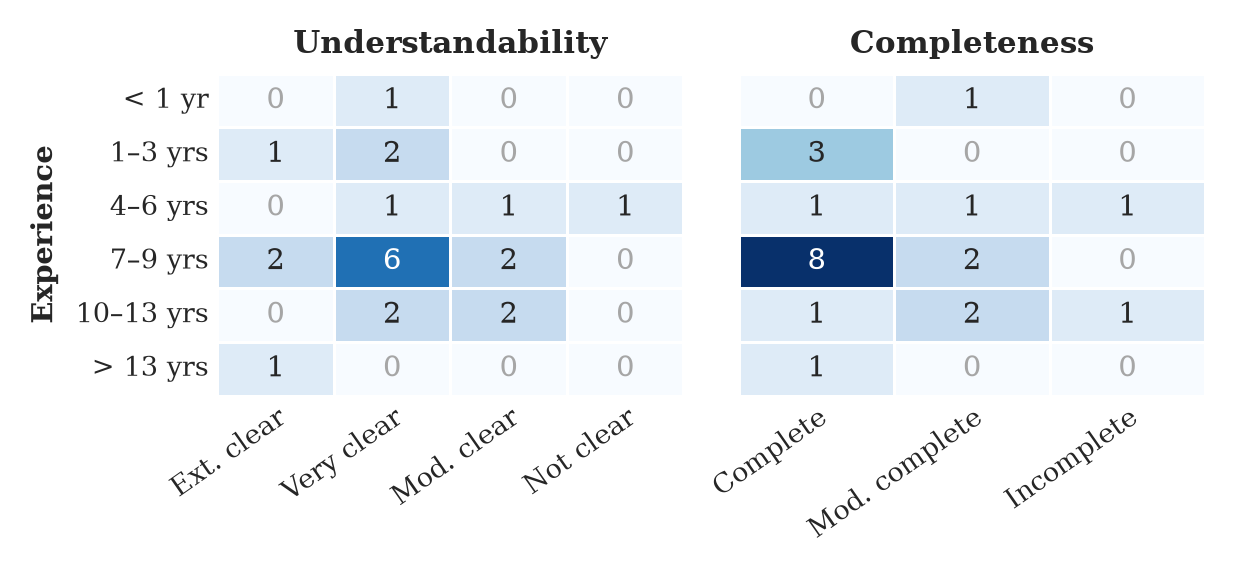

In [20]:
# ---------------------------------------------------------------------------
# Typography (IEEE: figure text should stay legible at ~7-8 pt when printed)
# ---------------------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 7,
    'axes.titlesize': 7.5,
    'axes.labelsize': 7,
    'xtick.labelsize': 6.5,
    'ytick.labelsize': 6.5,
    'pdf.fonttype': 42,   # embed TrueType fonts (IEEE PDF eXpress friendly)
    'ps.fonttype': 42,
})

exp_labels = ['< 1 yr', '1–3 yrs', '4–6 yrs', '7–9 yrs', '10–13 yrs', '> 13 yrs']

# ---------------------------------------------------------------------------
# 1. Prepare data
# ---------------------------------------------------------------------------
def build_ct(column, order, col_labels):
    ct = (pd.crosstab(completed_df['p5js_experience'], completed_df[column])
            .reindex(index=exp_order, columns=order, fill_value=0))
    ct.index = exp_labels
    ct.columns = col_labels
    return ct


ct_clarity = build_ct('rating_clarity', clarity_order,
                      ['Ext. clear', 'Very clear', 'Mod. clear', 'Not clear'])
ct_completeness = build_ct('rating_completeness', completeness_order,
                           ['Complete', 'Mod. complete', 'Incomplete'])

# Titles updated: removed "Taxonomy "
panels = [
    (ct_clarity, 'Understandability'),
    (ct_completeness, 'Completeness'),
]

# Shared colour scale so shades are comparable between the two panels
vmax = max(ct.values.max() for ct, _ in panels)

# ---------------------------------------------------------------------------
# 2. Single-row Layout
# ---------------------------------------------------------------------------
# Use subplots in a 1-row, 2-column grid sharing the y-axis
fig, axes = plt.subplots(
    nrows=1, 
    ncols=2, 
    sharey=True, 
    figsize=(4, 1.8), 
    layout='constrained'
)

for idx, (ax, (data, title)) in enumerate(zip(axes, panels)):
    sns.heatmap(
        data,
        annot=True,
        fmt='d',
        cmap='Blues',
        vmin=0,
        vmax=vmax,
        cbar=False,
        linewidths=0.6,
        linecolor='white',
        annot_kws={'size': 7},
        ax=ax,
    )

    # De-emphasise zero cells so the non-zero counts stand out
    for txt in ax.texts:
        if txt.get_text() == '0':
            txt.set_color('0.65')

    ax.set_title(title, loc='center', fontweight='bold', pad=5)
    ax.set_xlabel('')
    
    # Y-axis handling: Only show title and ticks on the first (left-most) axis
    if idx == 0:
        ax.set_ylabel('Experience', fontweight='bold')
    else:
        ax.set_ylabel('')
        ax.tick_params(axis='y', left=False)  # remove y ticks on right panel

    ax.tick_params(axis='both', which='both', length=0, pad=2)

    plt.setp(ax.get_xticklabels(), rotation=35, ha='right', va='top', rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0)

plt.savefig('taxonomy_evaluation_1_row.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()

# Qualitative